> **Experiment F1: FedAvg and a matched centralized comparator**
> Guide: [F1 federated learning](../docs/FEDAVG.md) · Config: [fed_fedavg.yaml](../configs/fed_fedavg.yaml)
> Depends on the validated E03 client dataset and the corrected Arm D baseline.

# Train the first federated baseline
This notebook runs real Flower FedAvg and TensorFlow training, one client at a time inside this Python process. It exchanges model weights through Flower's aggregation strategy. It does not start Ray, a gRPC service or separate machines. It is an algorithm simulation, not a deployment or a privacy guarantee. The centralized comparator deliberately reads the same processed client arrays.

On Kaggle attach the updated `windturbine-client-bridge.zip` and the saved E03 dataset. Set `WT_CLIENT_DATASET` to the folder containing `dataset_manifest.json`. A GPU is optional. Outputs stay under `/kaggle/working`; the attached inputs are never edited. The real-data default expects all 22 turbines, 58 events, and the exact E03 manifest used by the accepted D run.

Full defaults come from YAML: 100 rounds and one local epoch per round. For a short **pilot**, explicitly set `WT_F1_ROUNDS=3`; the resolved configuration records this change. `WT_F1_SMOKE=1` instead builds a tiny synthetic dataset and runs two rounds of real training on CPU. Its results are execution checks, not evidence about wind turbines. No stored outputs are included in this notebook.

## 1. Load the exact shared source
Local checkout, attached source bundle and an explicit published git revision are supported. `WT_REPO_ROOT` and `WT_REPO_REF` are mutually exclusive. A missing explicit source fails instead of choosing a different source silently. Bundle files are checked against their manifest before imports.

In [1]:
import os, sys, json, zipfile, subprocess, hashlib
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd

os.environ.setdefault("FLWR_TELEMETRY_ENABLED", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
SMOKE = os.environ.get("WT_F1_SMOKE", "0") == "1"
if SMOKE:
    # Small deterministic CPU smoke avoids consuming GPU resources.
    os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
    os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
    os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
WORK_ROOT = Path(os.environ.get("WT_WORK_ROOT", "/kaggle/working" if Path("/kaggle/input").exists() else str(Path.cwd())))
WORK_ROOT.mkdir(parents=True, exist_ok=True)
MODULE = Path("src/windturbine/federated/fedavg.py")
explicit_root, requested_ref = os.environ.get("WT_REPO_ROOT"), os.environ.get("WT_REPO_REF")
if explicit_root and requested_ref:
    raise ValueError("Choose WT_REPO_ROOT or WT_REPO_REF, not both")
REPO, bundle_sha256, resolved_ref = None, None, None
if explicit_root:
    REPO = Path(explicit_root)
    if not (REPO / MODULE).is_file():
        raise RuntimeError("WT_REPO_ROOT does not contain the client bridge: " + str(REPO))
elif requested_ref:
    REPO = WORK_ROOT / "windturbine-client-bridge-git"
    if not REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/PranavMundhra/Wind-Turbine.git", str(REPO)], check=True)
    subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", requested_ref], check=True)
    resolved_ref = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], check=True, capture_output=True, text=True).stdout.strip()
    expected_ref = subprocess.run(["git", "-C", str(REPO), "rev-parse", requested_ref + "^{commit}"], check=True, capture_output=True, text=True).stdout.strip()
    assert resolved_ref == expected_ref, "Requested source revision was not selected"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    if Path("/kaggle/input").exists():
        candidates += [p.parent.parent.parent.parent for p in Path("/kaggle/input").rglob("src/windturbine/federated/fedavg.py")]
    REPO = next((p for p in candidates if (p / MODULE).is_file()), None)
    if REPO is None and Path("/kaggle/input").exists():
        bundles = list(Path("/kaggle/input").rglob("windturbine-client-bridge.zip"))
        if len(bundles) > 1:
            raise RuntimeError("Attach only one source ZIP, or set WT_REPO_ROOT")
        if bundles:
            bundle_sha256 = hashlib.sha256(bundles[0].read_bytes()).hexdigest()
            target = WORK_ROOT / ("windturbine-source-" + bundle_sha256[:16])
            with zipfile.ZipFile(bundles[0]) as archive:
                names = archive.namelist()
                if len(names) != len(set(names)):
                    raise ValueError("Duplicate paths in source archive")
                for name in names:
                    if "\\" in name or not (target / name).resolve().is_relative_to(target.resolve()):
                        raise ValueError("Unsafe source archive path")
                package_manifest = json.loads(archive.read("bridge_bundle_manifest.json"))
                if package_manifest.get("format_version") != 1 or not isinstance(package_manifest.get("files"), dict):
                    raise ValueError("Unsupported source bundle manifest")
                files = package_manifest["files"]
                if set(names) != set(files) | {"bridge_bundle_manifest.json"}:
                    raise ValueError("Source bundle file list does not match manifest")
                for name, digest in files.items():
                    if hashlib.sha256(archive.read(name)).hexdigest() != digest:
                        raise ValueError("Source bundle hash mismatch: " + name)
                archive.extractall(target)
            REPO = target
if REPO is None or not (REPO / MODULE).is_file():
    raise RuntimeError("Attach windturbine-client-bridge.zip as a Kaggle Dataset (internet off works), "
                       "or attach a source checkout and set WT_REPO_ROOT. Optional internet mode: "
                       "set WT_REPO_REF to a published commit/tag containing src/windturbine/federated/fedavg.py.")
# Also verify an already extracted source bundle before importing any package code.
if (REPO / "bridge_bundle_manifest.json").is_file():
    package_manifest = json.loads((REPO / "bridge_bundle_manifest.json").read_text(encoding="utf-8"))
    if package_manifest.get("format_version") != 1:
        raise ValueError("Unsupported extracted source bundle")
    for name, digest in package_manifest["files"].items():
        source_path = (REPO / name).resolve()
        if not source_path.is_relative_to(REPO.resolve()) or hashlib.sha256(source_path.read_bytes()).hexdigest() != digest:
            raise ValueError("Extracted source bundle hash mismatch: " + name)
source_notebooks = [REPO / "notebooks" / name for name in ("13_arm_local_turbine.ipynb", "20_federated_clients.ipynb", "30_fedavg.ipynb")]
source_files = sorted([*REPO.glob("src/windturbine/**/*.py"), *REPO.glob("configs/*.yaml"),
                       *(p for p in source_notebooks if p.is_file())])
source_hashes = {p.relative_to(REPO).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
SOURCE_IDENTITY = {"source_tree_sha256": hashlib.sha256(json.dumps(source_hashes, sort_keys=True).encode()).hexdigest(),
                   "source_files": source_hashes, "bundle_sha256": bundle_sha256,
                   "requested_git_ref": requested_ref, "resolved_git_commit": resolved_ref}
sys.path.insert(0, str(REPO / "src"))
from windturbine.config import load_config
from windturbine.data.clients import build_client_dataset, load_client_dataset
print("Source:", REPO)
print("Source identity:", json.dumps(SOURCE_IDENTITY, indent=2))

Source: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine
Source identity: {
  "source_tree_sha256": "a5a7793902a70be20f104ce44bf126b7c84d89359e877241c54df455e0c5b4b4",
  "source_files": {
    "configs/arm_isolated.yaml": "ab352789a22a1d3cfe52d6854ebe095a04e85be89b10e0d51beedd3694ec8af1",
    "configs/arm_local_turbine.yaml": "8db53eded3df967c36e65c4a4d3712438a24581bc2a3abb6fb74520a59261795",
    "configs/arm_pooled.yaml": "c2c70de648928f873760115a5f405f3abb44ca6fe663cb9ee7054cb79c69cfb7",
    "configs/arm_pooled_dedup.yaml": "485e5470df67831de28dde349d7874554857f9cf9b4d0b7ccba1ba717f40b34d",
    "configs/base.yaml": "16668bbdc1a309e8c60d5c8fcc7d831bed2b7fb5b72eb28cfbb19d461a6e7533",
    "configs/clients.yaml": "41cdfee241855f0eb93d228d471b9a8c1224214155b539a25e96e5f0b1121f52",
    "configs/fed_fedavg.yaml": "d538f349350da04a4addcca612adcca1e3fb4e90fec9e699eee1c6a35a1f5be9",
    "configs/fed_fedprox.yaml": "c747ea630eac78e088756a5a736a611ad152153d3544d37d5b7c5954d4a0e57b",
    "configs/

## 2. Check training dependencies
Flower 1.40.0 is the tested aggregation version. TensorFlow 2.21.0 is the local validation version. Keep Kaggle's existing TensorFlow if it is compatible; this notebook does not install or upgrade packages automatically. Missing Flower: install `flwr==1.40.0` in a separate setup cell with internet enabled, or attach compatible wheels and install with `pip install --no-index --find-links=/kaggle/input/YOUR-WHEELS flwr==1.40.0`. For a missing TensorFlow runtime, use a compatible TensorFlow environment or the tested `tensorflow==2.21.0` package. Restart the kernel after changing binary packages. Package versions are saved with the run.

In [2]:
from importlib import metadata
missing = []
for package in ("flwr", "tensorflow"):
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        missing.append(package)
if missing:
    raise RuntimeError("Missing training packages: " + ", ".join(missing) +
                       ". Follow the setup instructions above; this notebook does not install packages automatically.")
if metadata.version("flwr") != "1.40.0":
    raise RuntimeError("Use the tested flwr==1.40.0 aggregation API; restart the kernel after installing it.")
try:
    import tensorflow as tf
    from windturbine.federated import run_fedavg, run_preflight, load_checkpoint
except ImportError as exc:
    raise RuntimeError("Training dependencies or shared F1 source are unavailable. Attach the updated source bundle and install compatible wheels.") from exc
print("TensorFlow devices:", tf.config.list_physical_devices())

flwr 1.40.0
tensorflow 2.21.0


TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 3. Resolve the experiment and saved client dataset
A model seed change does not rebuild or resplit E03. Training and evaluation use its persisted client arrays and status-only evaluation masks. The fingerprint hash is a data-identity check, not a claim that clients are statistically independent.

In [3]:
from datetime import datetime, timezone
CFG = load_config(REPO / "configs/base.yaml", REPO / "configs/fed_fedavg.yaml")
CFG = replace(CFG, seed=int(os.environ.get("WT_SEED", CFG.seed)))
if os.environ.get("WT_F1_ROUNDS"):
    rounds = int(os.environ["WT_F1_ROUNDS"])
    if rounds < 1:
        raise ValueError("WT_F1_ROUNDS must be positive")
    CFG = replace(CFG, extra={**CFG.extra, "rounds": rounds})
if SMOKE:
    # Synthetic data exists only to exercise the full export/training/readback path.
    raw_root = WORK_ROOT / "f1_synthetic_care"
    farm_dir = raw_root / CFG.farm
    datasets = farm_dir / "datasets"
    datasets.mkdir(parents=True, exist_ok=True)
    events = []
    for eid in range(1, 5):
        aid = (eid - 1) // 2 + 1
        times = pd.date_range("2024-01-01", periods=100, freq="10min")
        values = np.arange(100, dtype=float) + eid * 1000
        frame = pd.DataFrame({"time_stamp": times, "asset_id": aid,
                              "train_test": ["train"] * 80 + ["prediction"] * 20,
                              "status_type_id": 0, "sensor_0_avg": values,
                              "wind_speed_3_avg": 6.0 + values / 10000,
                              "power_30_avg": 0.5 + values / 10000})
        frame.loc[80, ["sensor_0_avg", "wind_speed_3_avg", "power_30_avg"]] = frame.loc[0, ["sensor_0_avg", "wind_speed_3_avg", "power_30_avg"]].to_numpy()
        frame.to_csv(datasets / f"comma_{eid}.csv", index=False)
        events.append({"event_id": eid, "event_label": "anomaly" if eid % 2 else "normal",
                       "event_start": times[85], "event_end": times[99]})
    pd.DataFrame(events).to_csv(farm_dir / "comma_event_info.csv", index=False)
    pd.DataFrame({"sensor_name": ["sensor_0", "wind_speed_3", "power_30"],
                  "description": ["temperature", "wind speed", "active power"]}).to_csv(farm_dir / "comma_feature_description.csv", index=False)
    split_cfg = replace(load_config(REPO / "configs/base.yaml", REPO / "configs/clients.yaml"),
                        val_block_hours=1, val_split_mode="blocked")
    CLIENT_ROOT = WORK_ROOT / "f1_smoke_clients"
    build_client_dataset(raw_root, CLIENT_ROOT, split_cfg, expected_clients=2, expected_events=4,
                         source_identity=SOURCE_IDENTITY)
    CFG = replace(CFG, hidden_layers=(8, 4, 2, 4, 8), batch_size=16,
                  val_block_hours=1, val_split_mode="blocked",
                  criticality_threshold=2, extra={**CFG.extra, "rounds": 2, "local_epochs": 1,
                    "n_clients": 2, "expected_clients": 2, "expected_events": 4,
                    "expected_dataset_manifest_sha256": hashlib.sha256((CLIENT_ROOT / "dataset_manifest.json").read_bytes()).hexdigest(),
                    "dataset_override_reason": "Synthetic CPU smoke only; not a research comparison"})
else:
    if os.environ.get("WT_CLIENT_DATASET"):
        CLIENT_ROOT = Path(os.environ["WT_CLIENT_DATASET"])
    else:
        candidates = list(Path("/kaggle/input").rglob("dataset_manifest.json")) if Path("/kaggle/input").exists() else []
        if len(candidates) != 1:
            raise RuntimeError("Attach the E03 output and set WT_CLIENT_DATASET to its folder containing dataset_manifest.json")
        CLIENT_ROOT = candidates[0].parent
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_ROOT = Path(os.environ.get("WT_F1_OUTPUT_ROOT", str(WORK_ROOT / CFG.output_dir / "F1" / stamp)))
if Path("/kaggle/input").exists() and not OUTPUT_ROOT.resolve().is_relative_to(Path("/kaggle/working").resolve()):
    raise ValueError("WT_F1_OUTPUT_ROOT must be inside /kaggle/working on Kaggle")
print("Mode:", "SYNTHETIC SMOKE" if SMOKE else "PILOT" if CFG.extra["rounds"] < 100 else "FULL")
print("Saved clients:", CLIENT_ROOT)
print("Run output:", OUTPUT_ROOT)
print("Resolved config:", CFG)

Mode: FULL
Saved clients: D:\wt_work\windturbine_clients
Run output: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F1\20261026T171256_313611Z
Resolved config: Config(farm='Wind Farm C', dataset_root='data/raw', cache_dir='data/cache', use_avg_only=True, drop_reactive=False, angle_transform=True, max_nan_fraction=0.3, normal_status_ids=(0, 2), wind_speed_cutin=3.0, wind_speed_rated=12.0, power_near_zero_thresh=0.02, hidden_layers=(133, 83, 20, 83, 133), learning_rate=0.0056, use_lr_plateau=False, lr_plateau_factor=0.5, lr_plateau_patience=4, noise_std=0.0, batch_size=64, max_epochs=200, early_stop_patience=10, seed=42, val_fraction=0.15, val_split_mode='blocked', val_block_hours=120, score_quantile=0.99, criticality_threshold=72, beta=0.5, care_weights=(1, 1, 1, 2), arm='fedavg', output_dir='results/runs', extra={'framework': 'flwr', 'strategy': 'fedavg', 'n_clients': 22, 'expected_clients': 22, 'expected_events': 58, 'fraction_fit': 1.0, 'rounds': 100, 'local_epochs': 1

## 4. Pass the algorithm and scoring gates
Before the real client models train, test Flower aggregation using unequal client sizes and a small SGD example. Check that collecting client event metrics gives the same CARE as direct evaluation. Failure stops the run. These gates check implementation; they do not predict that FL will beat local training.

In [4]:
preflight = run_preflight()
assert preflight["passed"], "Preflight gates did not pass"
print(json.dumps(preflight, indent=2))

W1026 22:42:57.048000 1208 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


{
  "passed": true,
  "sgd_equivalence": {
    "passed": true,
    "rounds": 3,
    "client_rows": [
      3,
      5,
      8
    ],
    "parameter_arrays": 2,
    "max_abs_error": 5.551115123125783e-17,
    "tolerance": 1e-12
  },
  "care_parity": {
    "passed": true,
    "events": 3,
    "results": {
      "Coverage": 1.0,
      "Earliness": 1.0,
      "Reliability": 1.0,
      "Accuracy": 1.0,
      "CARE": 1.0,
      "support": {
        "coverage": 1,
        "earliness": 1,
        "accuracy": 2
      },
      "event_confusion": {
        "tp": 1,
        "fp": 0,
        "fn": 0,
        "tn": 2
      },
      "n_anomaly_events": 1,
      "n_normal_events": 2
    }
  },
  "tensorflow_compatibility": {
    "passed": true,
    "clients": 3,
    "validation_mse": 0.3141769187054198,
    "checkpoint_roundtrip": true,
    "keras_backend": "torch 2.11.0+cu128"
  }
}


## 5. Run FedAvg and the matched centralized comparator
Each round starts every client from the same server weights. Client updates are weighted by retained training rows. Preprocessing stays local and unchanged. Validation selects the checkpoint; prediction/test scores never select the model. The centralized comparator starts from the same initial weights and trains on the union of those same processed training arrays with a recorded compute budget. Its pooled matrix uses each client's existing scaler.

This is the first algorithm baseline. Real distributed communication, secure aggregation and client dropout are later experiments. No test-set tuning or automatic claim of improvement is made.

In [5]:
run_manifest = run_fedavg(CLIENT_ROOT, OUTPUT_ROOT, CFG,
                          source_identity=SOURCE_IDENTITY, run_centralized=True)
print("Completed branches:", list(run_manifest["branches"]))

FedAvg round 1/100: validation MSE 1.10063 (29.4s)
Projected total runtime: 1.88 h (limit 11 h)


FedAvg round 2/100: validation MSE 0.745472 (32.0s)
Projected total runtime: 2.03 h (limit 11 h)


FedAvg round 3/100: validation MSE 0.622552 (32.9s)
Projected total runtime: 2.08 h (limit 11 h)


FedAvg round 4/100: validation MSE 0.544088 (33.2s)


FedAvg round 5/100: validation MSE 0.508798 (37.5s)


...

Centralized epoch 97/100: validation MSE 0.899343


Centralized epoch 98/100: validation MSE 0.906661


Centralized epoch 99/100: validation MSE 0.910131


Centralized epoch 100/100: validation MSE 0.909561


Completed branches: ['fedavg', 'centralized']


## 6. Verify the saved run and reload checkpoints
Do not trust an interrupted export. Check its completion marker and hashes before reading results. Both branches use the same saved dataset, feature order, per-client threshold policy and shared CARE evaluator.

In [6]:
manifest_path = OUTPUT_ROOT / "manifest.json"
print("Run artifacts:", OUTPUT_ROOT)
for relative, expected_hash in run_manifest["artifacts"].items():
    artifact = (OUTPUT_ROOT / relative).resolve()
    assert artifact.is_relative_to(OUTPUT_ROOT.resolve()), "Unsafe artifact path"
    assert hashlib.sha256(artifact.read_bytes()).hexdigest() == expected_hash, relative
assert (OUTPUT_ROOT / "COMPLETE").is_file(), "Run was not completely published"
checkpoint_counts = {}
for branch, info in run_manifest["branches"].items():
    # The core reloads selected weights and verifies their evaluation before publishing.
    checkpoint_path = OUTPUT_ROOT / info["checkpoint"]
    weights = load_checkpoint(checkpoint_path)
    assert weights and all(np.isfinite(w).all() for w in weights)
    checkpoint_counts[branch] = len(weights)
print("Reloaded checkpoint tensors:", checkpoint_counts)

Run artifacts: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F1\20261026T171256_313611Z
Reloaded checkpoint tensors: {'fedavg': 12, 'centralized': 12}


## 7. Read the results and training curves
The D reference CARE is **0.639852** only for the accepted dataset manifest below. A synthetic run or a different export cannot claim an improvement over that reference. Compare several seeds after the pipeline is validated; a pilot is not a final result.

FedAvg can be better or worse than local and centralized training. Keep the recorded results, selected round, validation curve and dataset hash together when reporting the experiment.

     branch  selected_epoch  Coverage  Earliness  Reliability  Accuracy     CARE                                           support                         event_confusion  n_anomaly_events  n_normal_events
     fedavg              26  0.352729    0.29421     0.654206  0.939891 0.636185 {'coverage': 27, 'earliness': 27, 'accuracy': 31} {'tp': 14, 'fp': 6, 'fn': 13, 'tn': 25}                27               31
centralized               2  0.316136    0.24376     0.722892  0.959842 0.640495 {'coverage': 27, 'earliness': 27, 'accuracy': 31} {'tp': 12, 'fp': 2, 'fn': 15, 'tn': 29}                27               31
D reference is not comparable to this dataset; no D improvement claim is valid.

 fedavg validation/training curve:
 epoch  validation_mse  participating_clients  fitting_rows  row_exposures                                                parameters_sha256
     0        1.141396                      0       1845037              0 9b084b69e2de97b36ded4c2952d843036379b445f710a4b5d98

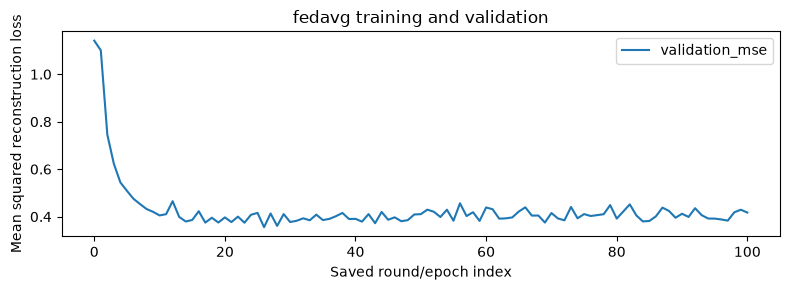


 centralized validation/training curve:
 epoch  validation_mse  row_exposures
     0        1.141396              0
     1        0.543097        1845037
     2        0.499545        1845037
     3        0.599694        1845037
     4        0.606170        1845037
     5        0.624362        1845037
     6        0.601638        1845037
     7        0.600330        1845037
     8        0.594326        1845037
     9        0.592630        1845037
    10        0.636032        1845037
    11        0.697108        1845037
    12        0.760320        1845037
    13        0.737541        1845037
    14        0.731820        1845037
    15        0.760953        1845037
    16        0.739375        1845037
    17        0.712250        1845037
    18        0.759957        1845037
    19        0.817108        1845037
    20        0.804039        1845037
    21        0.761072        1845037
    22        0.703408        1845037
    23        0.859254        1845037
    24   

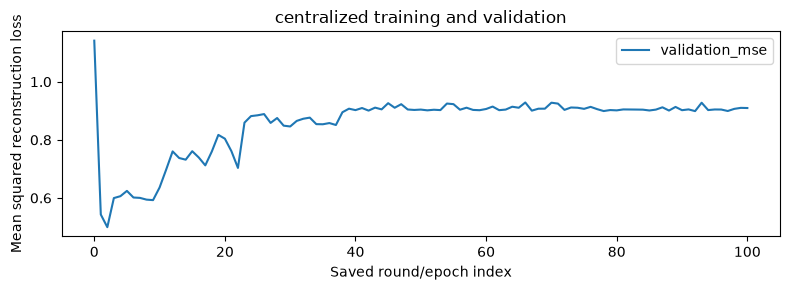

Keep the entire run folder for review: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F1\20261026T171256_313611Z


In [7]:
reference_hash = "bb2ed3ffc84adbf79bbba624941090acd91831097f427b38b2e20885d4b0b1d1"
dataset_hash = hashlib.sha256((CLIENT_ROOT / "dataset_manifest.json").read_bytes()).hexdigest()
rows = []
for branch, info in run_manifest["branches"].items():
    rows.append({"branch": branch, "selected_epoch": info.get("selected_epoch"), **info["results"]})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
if dataset_hash == reference_hash and not SMOKE:
    print("Matched D dataset. Accepted D CARE reference: 0.639852")
else:
    print("D reference is not comparable to this dataset; no D improvement claim is valid.")
for branch, info in run_manifest["branches"].items():
    history_path = OUTPUT_ROOT / info.get("rounds", info["history"])
    history = pd.read_csv(history_path)
    print("\n", branch, "validation/training curve:")
    print(history.to_string(index=False))
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("Install matplotlib if you also want an inline curve; the full values are shown above.")
    else:
        loss_columns = [column for column in history.columns if "loss" in column.lower() or "mse" in column.lower()]
        if loss_columns:
            axis_column = next((column for column in ("round", "epoch", "server_round") if column in history), None)
            ax = history.plot(x=axis_column, y=loss_columns, title=branch + " training and validation", figsize=(8, 3))
            ax.set_xlabel("Saved round/epoch index")
            ax.set_ylabel("Mean squared reconstruction loss")
            plt.tight_layout()
            plt.show()
print("Keep the entire run folder for review:", OUTPUT_ROOT)